# Лабораторна 5, частина 1. Власне донавчання: модерація україномовних повідомлень

**Задача:** визначити, чи містить коротке україномовне повідомлення вульгарну / ненормативну лексику (`TOXIC`) чи ні (`NOT_TOXIC`).
**Модель:** Qwen3-1.7B. **Метод:** SFT з LoRA. **Дані:** `ukr-detect/ukr-toxicity-dataset-seminatural`.

План:
1. Дані: завантаження, перевірка на дублікати й витік між наборами, поділ.
2. Модель до донавчання: базові рівні й найкращий промпт (вибір промпту — на validation, оцінка — на test).
3. Донавчання LoRA: гіперпараметри, криві loss, час і памʼять.
4. Порівняння до / після на тому самому тестовому наборі, аналіз помилок, перевірка загальних запитів.
5. Звіт (розділ 1.6).

> ⚠️ **Датасет містить реальну ненормативну лексику** — це і є предмет задачі, тому клітинки з прикладами друкують такі тексти.
> Числа й висновки в коментарях і звіті взято з мого запуску в Colab (GPU Tesla T4, seed 42).
> Запуск: *Runtime → Change runtime type → T4 GPU*, далі *Run all*. Найдовші клітинки — тренування й три оцінювання на тестовому наборі;
> для швидкого прогону зменшіть `N_TEST` і `MAX_STEPS` у клітинці з налаштуваннями.

## 1.1. Задача

**Користувач і сценарій.** Модератор спільноти (чат, коментарі під новинами, Telegram-група). Система перевіряє кожне нове повідомлення
й або одразу ховає його, або позначає для ручної перевірки.

**Вхід:** одне коротке повідомлення українською (твіт, коментар, речення).
**Вихід:** рівно одне слово: `TOXIC` (повідомлення містить вульгарну або ненормативну лексику, зокрема замасковану) або `NOT_TOXIC`.

**Чому потрібне донавчання, а не промпт чи RAG** (це гіпотези, які ми перевіряємо експериментом нижче):

1. **Визначення мітки — це конвенція розмітки, а не загальне знання.** У даних `TOXIC` означає вульгарну лексику (так розмічено датасет), тоді як загальна
   модель за слово «токсичний» розуміє ширше: образи, агресію, сарказм, політично заряджені висловлювання. Межу «наша конвенція» важко передати текстом промпту; промпт доводиться
   писати довго й підганяти.
2. **Ціна та швидкість.** Детальний промпт з визначенням і прикладами повторюється в кожному запиті. Модерація — це тисячі коротких повідомлень, тому довгий промпт множиться
   на весь потік. Після донавчання достатньо одного рядка інструкції.
3. **Жорсткий формат відповіді.** Нам потрібне одне слово, без пояснень і розмітки, які загальні моделі люблять додавати.
4. **RAG тут не допомагає:** немає бази знань, з якої можна дістати відповідь; проблема в межі рішення, а не в нестачі фактів.
5. **Приватність і вартість:** мала модель (1,7 млрд) можна запускати власним сервером, без передачі повідомлень стороннім API.

**Уточнення за результатами експерименту** (деталі нижче, в аналізі помилок і звіті):
- Конвенція розмітки ширша, ніж «вульгарна лексика» з картки датасету: у `TOXIC` потрапляють також образливі слова-слюри й зневажливий сленг (на кшталт «хохол», «педик», «тьолка»),
  а частина міток — шум автоматичної розмітки за ключовими словами.
- Пункт 3 (жорсткий формат відповіді) **не підтвердився**: Qwen3-1.7B видає чисту відповідь (рівно `TOXIC` або `NOT_TOXIC`) у 100% випадків і без донавчання.
  Виграш від донавчання — у межі рішення та довжині промпту, а не у форматі.

In [1]:
# trl — SFT, peft — LoRA; torchao з Colab конфліктує з peft, для цієї роботи він не потрібен
!pip install -q "transformers>=4.55.0" "trl>=1.17" "peft" "datasets" "accelerate" "scikit-learn" "matplotlib"
!pip uninstall -q -y torchao

In [2]:
import gc
import json
import os
import random
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from peft import LoraConfig
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

SEED = 42
set_seed(SEED)

assert torch.cuda.is_available(), "Потрібна GPU: Runtime → Change runtime type → T4 GPU"
print(f"GPU: {torch.cuda.get_device_name()}")
print(f"Памʼять GPU: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

GPU: Tesla T4
Памʼять GPU: 15.6 GB


In [3]:
# ---- Налаштування експерименту (усе, що варто змінювати, зібрано тут) ----
MODEL_NAME = "Qwen/Qwen3-1.7B"
DATASET_NAME = "ukr-detect/ukr-toxicity-dataset-seminatural"

N_TRAIN, N_VAL, N_TEST = 3000, 300, 1000   # розміри підвибірок
MAX_STEPS = 250                            # кроків тренування (по 8 прикладів = 2000 прикладів, ≈ 0,67 епохи)
LEARNING_RATE = 2e-4
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05

LABELS = ["TOXIC", "NOT_TOXIC"]

## 1.2. Модель і дані

### Дані

| | |
|---|---|
| **Джерело** | Hugging Face: [`ukr-detect/ukr-toxicity-dataset-seminatural`](https://huggingface.co/datasets/ukr-detect/ukr-toxicity-dataset-seminatural); стаття Dementieva та ін., *Toxicity Classification in Ukrainian* (2024, arXiv:2404.17841) |
| **Ліцензія** | OpenRAIL++ (за карткою датасету): дозволяє використання, але з обмеженнями на шкідливе застосування; адаптер, навчений на ньому, варто публікувати з тією ж ліцензією |
| **Розмір** | train 12 682, validation 4 227, test 4 214 прикладів (до очищення) |
| **Формат** | parquet; колонки `text` (рядок) і `tags` (число: 1 — токсичне, 0 — ні; перевіряємо нижче) |
| **Як створено** | напівавтоматично: токсичні — україномовні твіти, відфільтровані за списком токсичних слів; нетоксичні — твіти та речення з новин і художньої літератури (UD Ukrainian IU); потім збалансовано за класом і джерелом |

Важлива особливість: у картці зазначено, що «токсичним» вважається те, що зазвичай називають **вульгарною або непристойною лексикою**. Розмітка отримана за ключовими словами, тому вона може бути шумною,
а нетоксичні тексти частково походять з іншого регістру (новини, проза), ніж токсичні (твіти). Це впливає на інтерпретацію результатів (див. аналіз помилок).

### Поділ
Використовуємо готові поділи `train / validation / test`, але додатково: (0) прибираємо приклади без мітки (у колонці `tags` трапляються пропуски), (1) видаляємо дублікати всередині кожного набору, (2) видаляємо з train і validation
усе, що трапляється в test (і з train те, що є у validation), (3) перевіряємо відсутність перетину, (4) беремо випадкові підвибірки з фіксованим seed.
Тестовий набір не використовується ні для тренування, ні для вибору промпту чи гіперпараметрів.

In [4]:
ds = load_dataset(DATASET_NAME)
print(ds)
print(ds["train"].features)


def tag_kind(tag):
    """Для підрахунку: пропуски (None / NaN) показуємо окремо, а не ламаємо на них сортування."""
    if tag is None:
        return "None"
    if tag != tag:
        return "NaN"
    return tag


for split in ds:
    print(f"{split:<11} значення tags:", dict(Counter(tag_kind(t) for t in ds[split]["tags"])))

README.md:   0%|          | 0.00/5.52k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.24MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  417kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/12682 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/4227 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/4214 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'tags'],
        num_rows: 12682
    })
    validation: Dataset({
        features: ['text', 'tags'],
        num_rows: 4227
    })
    test: Dataset({
        features: ['text', 'tags'],
        num_rows: 4214
    })
})
{'text': Value('string'), 'tags': Value('float64')}
train       значення tags: {1.0: 6244, 0.0: 6362, 'None': 76}
validation  значення tags: {0.0: 2071, 1.0: 2131, 'None': 25}
test        значення tags: {1.0: 2114, 0.0: 2088, 'None': 12}


In [5]:
# У колонці tags трапляються пропуски (None / NaN): такі приклади не мають мітки, тож їх не можна ні тренувати, ні оцінювати.
# Прибираємо їх до всіх інших кроків (так само порожні тексти).
def has_valid_label(example):
    text = example["text"]
    return isinstance(text, str) and text.strip() != "" and example["tags"] in (0.0, 1.0)


n_raw = {name: len(split) for name, split in ds.items()}
ds = ds.filter(has_valid_label)
for name in ds:
    print(f"{name:<11} видалено без мітки / з порожнім текстом: {n_raw[name] - len(ds[name]):>5} із {n_raw[name]}")
print("Значення tags після очищення:", dict(Counter(ds["train"]["tags"])))

Filter:   0%|          | 0/12682 [00:00<?, ? examples/s]

Filter:   0%|          | 0/4227 [00:00<?, ? examples/s]

Filter:   0%|          | 0/4214 [00:00<?, ? examples/s]

train       видалено без мітки / з порожнім текстом:    76 із 12682
validation  видалено без мітки / з порожнім текстом:    25 із 4227
test        видалено без мітки / з порожнім текстом:    12 із 4214
Значення tags після очищення: {1.0: 6244, 0.0: 6362}


In [6]:
# ⚠️ Нижче друкуються приклади з ненормативною лексикою. Перевіряємо, що tags == 1 справді означає «токсичне».
for tag in (1.0, 0.0):
    print(f"\n--- tags = {tag} ---")
    subset = ds["train"].filter(lambda ex: ex["tags"] == tag).shuffle(seed=SEED).select(range(5))
    for t in subset["text"]:
        print("•", t[:200].replace("\n", " "))


--- tags = 1.0 ---


Filter:   0%|          | 0/12606 [00:00<?, ? examples/s]

• -ти її не любиш? -я до неї ніяк не ставлюся, окрім як до людини, з якою готовий був проїбати необмежену кількість років.
• царьов хуйло!!! ла-ла-ла-ла-ла-ла  :)
• точно пиздилася...може то сєкс був??
• купила збірку кросвордів, а вона без анекдотів. ви шо, їбанулися, я зараз поліцію викличу!
• всьо лучшеє в жизні случаєца нєажиданна))

--- tags = 0.0 ---


Filter:   0%|          | 0/12606 [00:00<?, ? examples/s]

• ну це ж як прикро, коли #цевартетвіту!, але не мооожна, не можна... побачать. )
• Ось, якщо за лінком відкриється, звісноhttps://pin.it/uenyvijh27yzgy 
• @andreyev_vova Кажи їм - справжні митці на замовлення не творять! ;)
• Все це робить негр , наче не слухаючи мелодії й ритму танцю , що совгає й колише цілу залу людських тіл в екстатичному захваті .
• Залежно які то привиди будуть


**Перевірка міток.** За прикладами вище `tags = 1` — токсичні (лайка й образи), `tags = 0` — нетоксичні (звичайні повідомлення, новини, проза), тож відповідність у функції `targets_of` правильна.

**Що показали пропуски в `tags`.** Колонка містить значення `None`: у train 76, у validation 25, у test 12 прикладів без мітки (разом 113). Їх прибрано до всіх інших кроків.
Після очищення й дедуплікації: train 12 536, validation 4 195, test 4 200 прикладів. Підвибірки для експерименту: **train 3000** (1495 TOXIC / 1505 NOT_TOXIC),
**validation 300** (151 / 149), **test 1000** (508 / 492). Перетину між наборами немає (перевірено `assert`).

**Приклади з датасету** (нецензурні слова замасковано зірочками):

- `tags = 1` (TOXIC): `царьов х***ло!!! ла-ла-ла-ла-ла-ла :)`
- `tags = 1` (TOXIC): `купила збірку кросвордів, а вона без анекдотів. ви шо, ї***нулися, я зараз поліцію викличу!`
- `tags = 0` (NOT_TOXIC): `@andreyev_vova Кажи їм - справжні митці на замовлення не творять! ;)`
- `tags = 0` (NOT_TOXIC): `Залежно які то привиди будуть`
- `tags = 0` (NOT_TOXIC): офіційний текст про ізоляцію домашніх тварин (перший тренувальний приклад)
- Шум розмітки вже видно в прикладах: `всьо лучшеє в жизні случаєца нєажиданна))` має `tags = 1`, хоча нецензурного слова в тексті немає.

In [7]:
def norm(text):
    """Нормалізація для пошуку дублікатів: регістр і пробіли не мають значення."""
    return " ".join(text.lower().split())


def dedup(split, forbidden):
    """Залишає по одному прикладу на кожен текст і прибирає тексти з множини forbidden."""
    seen, keep = set(forbidden), []
    for i, text in enumerate(split["text"]):
        key = norm(text)
        if key not in seen:
            seen.add(key)
            keep.append(i)
    return split.select(keep)


test_clean = dedup(ds["test"], set())
test_keys = {norm(t) for t in test_clean["text"]}
val_clean = dedup(ds["validation"], test_keys)
val_keys = {norm(t) for t in val_clean["text"]}
train_clean = dedup(ds["train"], test_keys | val_keys)

for name, before, after in [("train", ds["train"], train_clean), ("validation", ds["validation"], val_clean), ("test", ds["test"], test_clean)]:
    print(f"{name:<11} до дедуплікації: {len(before):>6}, після: {len(after):>6}")


def take(split, n):
    return split.shuffle(seed=SEED).select(range(min(n, len(split))))


train_ds, val_ds, test_ds = take(train_clean, N_TRAIN), take(val_clean, N_VAL), take(test_clean, N_TEST)


def targets_of(split):
    return ["TOXIC" if int(tag) == 1 else "NOT_TOXIC" for tag in split["tags"]]


train_texts, val_texts, test_texts = train_ds["text"], val_ds["text"], test_ds["text"]
train_targets, val_targets, test_targets = targets_of(train_ds), targets_of(val_ds), targets_of(test_ds)

# Перевірка: жодного перетину між наборами
tr, va, te = ({norm(t) for t in x} for x in (train_texts, val_texts, test_texts))
assert not (tr & va) and not (tr & te) and not (va & te), "Є перетин між наборами!"
print("\nПеретину між train / validation / test немає")

dist = pd.DataFrame({
    "train": Counter(train_targets), "validation": Counter(val_targets), "test": Counter(test_targets),
}).fillna(0).astype(int)
print(dist)

train       до дедуплікації:  12606, після:  12536
validation  до дедуплікації:   4202, після:   4195
test        до дедуплікації:   4202, після:   4200

Перетину між train / validation / test немає
           train  validation  test
NOT_TOXIC   1505         149   492
TOXIC       1495         151   508


In [8]:
# Формат messages для SFT (як у демо 3): system — коротка інструкція, user — повідомлення, assistant — правильна мітка
SHORT_PROMPT = "Classify the Ukrainian message as TOXIC or NOT_TOXIC. Reply with one word."


def to_messages(example):
    return {
        "messages": [
            {"role": "system", "content": SHORT_PROMPT},
            {"role": "user", "content": example["text"]},
            {"role": "assistant", "content": "TOXIC" if int(example["tags"]) == 1 else "NOT_TOXIC"},
        ],
        "chat_template_kwargs": {"enable_thinking": False},   # без міркувань: одразу відповідь
    }


# Тренувальні набори містять лише колонки messages і chat_template_kwargs;
# «сирі» train_ds / val_ds / test_ds лишаються для оцінювання
train_sft = train_ds.map(to_messages, remove_columns=train_ds.column_names)
val_sft = val_ds.map(to_messages, remove_columns=val_ds.column_names)
train_sft[0]["messages"]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

[{'content': 'Classify the Ukrainian message as TOXIC or NOT_TOXIC. Reply with one word.',
  'role': 'system'},
 {'content': 'Тимчасово ізольовані домашні тварини протягом семи днів з дня їх вилову повинні бути обстежені і після висновків державної установи ветеринарної медицини про стан здоров’я тварин повертаються власникам ( після сплати витрат на обстеження і утримання ) , а в разі виявлення обставин , що можуть загрожувати життю та здоров’ю оточуючих , передаються спеціалізованим організаціям для подальшого лікування чи умертвіння .',
  'role': 'user'},
 {'content': 'NOT_TOXIC', 'role': 'assistant'}]

### Модель

**Qwen3-1.7B** (`Qwen/Qwen3-1.7B`) — обґрунтування вибору:

- **Instruct, а не base.** Це модель після постнавчання: вона вже виконує інструкції на кшталт «відповідай одним словом». Тому порівняння «до» з промптом
  осмислене (це чесний базовий рівень), а SFT лише закріплює конвенцію міток, а не вчить діалогового формату з нуля, як довелося б із base-моделлю.
- **Багатомовність.** Qwen3 заявлено як модель із підтримкою 119 мов, зокрема української.
- **Розмір.** 1,7 млрд параметрів у fp16 займають близько 3,4 GB, тож LoRA вміщується в безкоштовну T4 (15 GB) із запасом. Менша модель (0.6B), імовірно, гірше розуміє українську (це я окремо не перевіряла),
  більша (4B) вже потребує QLoRA або суттєво більше часу, а для модерації потоку повідомлень важлива швидкість.
- Режим міркування вимикаємо (`enable_thinking=False`): для класифікації він лише додав би токени й затримку.

In [9]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Ваги збережено в bfloat16, але T4 його апаратно не підтримує, тому завантажуємо у float16
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16, device_map="auto")
print(f"{MODEL_NAME}: {model.num_parameters() / 1e9:.2f} млрд параметрів, "
      f"памʼять GPU після завантаження: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

# Скільки токенів займає діалог: перевіряємо, чи вистачить max_length=256 у тренуванні
lengths = [
    len(tokenizer(tokenizer.apply_chat_template(ex["messages"], tokenize=False, enable_thinking=False))["input_ids"])
    for ex in train_sft.select(range(min(300, len(train_sft))))
]
print(f"Довжина діалогу в токенах: середня {np.mean(lengths):.0f}, 95-й перцентиль {np.percentile(lengths, 95):.0f}, максимум {max(lengths)}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen/Qwen3-1.7B: 1.72 млрд параметрів, памʼять GPU після завантаження: 3.4 GB
Довжина діалогу в токенах: середня 87, 95-й перцентиль 154, максимум 235


## 1.3. Модель до донавчання

### Метрики

Класи в даних збалансовані, тому **accuracy** інтерпретується просто. Але для модерації ціна помилок різна, тож додатково:

- **Precision (TOXIC)** — з того, що модель позначила токсичним, яка частка справді токсична. Низька → ховаємо нормальні повідомлення (цензура).
- **Recall (TOXIC)** — яку частку справді токсичних повідомлень модель знайшла. Низький → вульгарність проходить.
- **F1 (TOXIC)** — їхнє гармонічне середнє; це **головна метрика** (за нею вибираємо промпт на validation).
- **Macro-F1** — F1, усереднений по обох класах.
- **Невалідні відповіді** — частка відповідей, з яких не вдалося зрозуміти мітку (рахуються як помилка);
  **чиста відповідь** — частка відповідей, що є точно `TOXIC` або `NOT_TOXIC` без зайвого тексту (для нашого формату це важливо).

Базові рівні: (1) «завжди найчастіший клас»; (2) простий TF-IDF + логістична регресія як нижня межа того, чого можна досягти без LLM
(вона покаже, наскільки задача розв'язується простою лексикою).

In [10]:
def parse_label(answer):
    """Повертає (мітка або None, чи відповідь була «чистою»: точно TOXIC / NOT_TOXIC)."""
    a = answer.strip().upper().replace("-", "_").replace(" ", "_")
    if a in LABELS:
        return a, True
    # «Поблажливий» розбір для відповідей на кшталт «Not toxic.» або «The message is toxic»
    if "NOT_TOXIC" in a or "NON_TOXIC" in a or "NONTOXIC" in a:
        return "NOT_TOXIC", False
    if "TOXIC" in a:
        return "TOXIC", False
    return None, False


def cls_metrics(preds, targets, clean_flags=None):
    """Метрики класифікації; None у preds (невалідна відповідь) рахується помилкою."""
    n = len(targets)

    def prf(pos):
        tp = sum(p == pos and t == pos for p, t in zip(preds, targets))
        fp = sum(p == pos and t != pos for p, t in zip(preds, targets))
        fn = sum(p != pos and t == pos for p, t in zip(preds, targets))
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        return precision, recall, f1

    p_toxic, r_toxic, f_toxic = prf("TOXIC")
    _, _, f_ok = prf("NOT_TOXIC")
    metrics = {
        "Accuracy, %": 100 * sum(p == t for p, t in zip(preds, targets)) / n,
        "Precision (TOXIC), %": 100 * p_toxic,
        "Recall (TOXIC), %": 100 * r_toxic,
        "F1 (TOXIC), %": 100 * f_toxic,
        "Macro-F1, %": 100 * (f_toxic + f_ok) / 2,
        "Невалідних відповідей, %": 100 * sum(p is None for p in preds) / n,
    }
    if clean_flags is not None:
        metrics["Чиста відповідь, %"] = 100 * sum(clean_flags) / n
    return metrics


def generate_batch(model, texts, system_prompt, max_new_tokens=16):
    """Відповіді моделі на список повідомлень одним батчем (жадібне декодування, без міркувань)."""
    prompts = [
        tokenizer.apply_chat_template(
            [{"role": "system", "content": system_prompt}, {"role": "user", "content": text}],
            tokenize=False, add_generation_prompt=True, enable_thinking=False,
        )
        for text in texts
    ]
    tokenizer.padding_side = "left"          # для генерації батчем доповнюємо зліва
    inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(model.device)
    tokenizer.padding_side = "right"
    with torch.no_grad():
        outputs = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tokenizer.pad_token_id)
    new_tokens = outputs[:, inputs["input_ids"].shape[1]:]
    return [a.strip() for a in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]


def evaluate(model, texts, targets, system_prompt, batch_size=32):
    """Повертає метрики, мітки та «сирі» відповіді моделі."""
    model.eval()
    answers = []
    for start in range(0, len(texts), batch_size):
        answers += generate_batch(model, texts[start:start + batch_size], system_prompt)
    parsed = [parse_label(a) for a in answers]
    preds = [p for p, _ in parsed]
    clean = [c for _, c in parsed]
    return cls_metrics(preds, targets, clean), preds, answers

In [11]:
# Базовий рівень 1: завжди найчастіший клас із тренувального набору
majority = Counter(train_targets).most_common(1)[0][0]
majority_metrics = cls_metrics([majority] * len(test_targets), test_targets)
print(f"Найчастіший клас у train: {majority}")

# Базовий рівень 2: TF-IDF на символьних n-грамах + логістична регресія (без LLM)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
clf = LogisticRegression(max_iter=1000).fit(vectorizer.fit_transform(train_texts), train_targets)
tfidf_preds = list(clf.predict(vectorizer.transform(test_texts)))
tfidf_metrics = cls_metrics(tfidf_preds, test_targets)

pd.DataFrame({"Найчастіший клас": majority_metrics, "TF-IDF + LogReg": tfidf_metrics}).round(1)

Найчастіший клас у train: NOT_TOXIC


,Найчастіший клас,TF-IDF + LogReg
"Accuracy, %",49.2,94.4
"Precision (TOXIC), %",0.0,94.0
"Recall (TOXIC), %",0.0,95.1
"F1 (TOXIC), %",0.0,94.5
"Macro-F1, %",33.0,94.4
"Невалідних відповідей, %",0.0,0.0


### Підбір найкращого промпту (на validation)

Три варіанти, від простого до складного:
- **P1** — мінімальна інструкція (це той самий короткий промпт, який використаємо після донавчання);
- **P2** — інструкція з **визначенням** мітки, яке відповідає конвенції розмітки (вульгарна лексика, зокрема замаскована; негатив без вульгарності — не токсичний);
- **P3** — P2 + шість прикладів із тренувального набору (few-shot).

Найкращий вибираємо за F1 (TOXIC) **на validation**, щоб не підлаштовуватись під тестовий набір.

In [12]:
P1 = SHORT_PROMPT

P2 = (
    "You are a content moderation classifier for Ukrainian-language social media text.\n"
    "Label the message TOXIC if it contains vulgar, obscene or profane language, including masked or abbreviated profanity "
    "(for example with replaced or omitted letters).\n"
    "Label it NOT_TOXIC otherwise: neutral, news or literary text, and also negative or critical remarks that contain no vulgar language.\n"
    "Reply with exactly one word: TOXIC or NOT_TOXIC."
)


def pick_examples(per_class=3, max_chars=100):
    """Беремо кілька коротких прикладів кожного класу з тренувального набору (фіксований seed)."""
    rng = random.Random(SEED)
    picked = []
    for label in LABELS:
        pool = [t for t, y in zip(train_texts, train_targets) if y == label and len(t) <= max_chars]
        picked += [(t.replace("\n", " "), label) for t in rng.sample(pool, per_class)]
    rng.shuffle(picked)
    return picked


FEWSHOT = pick_examples()
P3 = P2 + "\n\nExamples:\n" + "\n".join(f"Message: {t}\nLabel: {y}" for t, y in FEWSHOT)

prompts = {"P1 мінімальний": P1, "P2 з визначенням": P2, "P3 з визначенням і 6 прикладами": P3}
val_results = {}
for name, prompt in prompts.items():
    metrics, _, _ = evaluate(model, val_texts, val_targets, prompt)
    metrics["Токенів у промпті"] = len(tokenizer(prompt)["input_ids"])
    val_results[name] = metrics
val_df = pd.DataFrame(val_results).round(1)
display(val_df)

best_name = val_df.loc["F1 (TOXIC), %"].idxmax()
BEST_PROMPT = prompts[best_name]
print("Найкращий промпт за F1 (TOXIC) на validation:", best_name)

,P1 мінімальний,P2 з визначенням,P3 з визначенням і 6 прикладами
"Accuracy, %",67.3,70.7,86.0
"Precision (TOXIC), %",88.4,89.9,83.0
"Recall (TOXIC), %",40.4,47.0,90.7
"F1 (TOXIC), %",55.5,61.7,86.7
"Macro-F1, %",64.8,69.0,86.0
"Невалідних відповідей, %",0.0,0.0,0.0
"Чиста відповідь, %",100.0,100.0,100.0
Токенів у промпті,20.0,87.0,296.0


Найкращий промпт за F1 (TOXIC) на validation: P3 з визначенням і 6 прикладами


**Найкращий — P3 (визначення + 6 прикладів): F1 (TOXIC) = 86,7%, accuracy = 86,0% на validation.** Для порівняння: P1 — 55,5% / 67,3%, P2 — 61,7% / 70,7%.

Чому так вийшло:

- **P1 і P2** мають високу precision (88,4% і 89,9%), але дуже низький recall (40,4% і 47,0%): модель обережна й пропускає більшість токсичних повідомлень. Визначення в P2 допомогло лише трохи (+6,2 п.п. F1):
  слово «токсичний» модель розуміє по-своєму, і текстом визначення не вдається передати, що саме вважає токсичним датасет.
- **P3:** приклади підняли recall до 90,7% (+43,7 п.п. проти P2) ціною меншої precision (83,0%). Тобто приклади «калібрують» межу рішення: показують, де саме проходить межа в цій розмітці.
- **Формат** у всіх трьох варіантів ідеальний: 100% відповідей — рівно `TOXIC` або `NOT_TOXIC`. Тож проблем із форматом у Qwen3-1.7B немає, відмінності лише в якості рішення.
- **Ціна:** P3 має 296 токенів проти 20 у P1, тобто промпт довший приблизно в 15 разів. Це і є причина, чому нас цікавить донавчання: воно має дати якість P3 за ціною P1.

In [13]:
# Оцінка «до» на ТЕСТОВОМУ наборі з найкращим промптом
t0 = time.time()
before_metrics, preds_before, answers_before = evaluate(model, test_texts, test_targets, BEST_PROMPT)
before_seconds = time.time() - t0
print(f"Промпт: {best_name}; оцінювання 1 набору: {before_seconds:.0f} с")

baseline_df = pd.DataFrame({
    "Найчастіший клас": majority_metrics,
    "TF-IDF + LogReg": tfidf_metrics,
    f"Qwen3-1.7B, {best_name}": before_metrics,
}).round(1)
baseline_df

Промпт: P3 з визначенням і 6 прикладами; оцінювання 1 набору: 119 с


,Найчастіший клас,TF-IDF + LogReg,"Qwen3-1.7B, P3 з визначенням і 6 прикладами"
"Accuracy, %",49.2,94.4,83.9
"Precision (TOXIC), %",0.0,94.0,82.0
"Recall (TOXIC), %",0.0,95.1,87.6
"F1 (TOXIC), %",0.0,94.5,84.7
"Macro-F1, %",33.0,94.4,83.9
"Невалідних відповідей, %",0.0,0.0,0.0
"Чиста відповідь, %",NaN,NaN,100.0


In [14]:
# 10 прикладів відповідей моделі до донавчання (⚠️ можливі нецензурні слова в текстах)
show_idx = list(range(10))
examples_before = pd.DataFrame({
    "text": [test_texts[i][:90].replace("\n", " ") for i in show_idx],
    "еталон": [test_targets[i] for i in show_idx],
    "відповідь моделі (до)": [answers_before[i] for i in show_idx],
})
examples_before

,text,еталон,відповідь моделі (до)
0,вмієш бути підаром то будь ним всєгда,TOXIC,TOXIC
1,@caliwinter насправді камера в моєму телефоні ...,NOT_TOXIC,NOT_TOXIC
2,значить в мене будуть самі круті макети!),NOT_TOXIC,TOXIC
3,@tinawine ой я ще забула про Castle,NOT_TOXIC,NOT_TOXIC
4,Статево найчутливіші місця тут — ділянка слизо...,NOT_TOXIC,NOT_TOXIC
5,@tetyanka_bell ага),NOT_TOXIC,NOT_TOXIC
6,@doc_vanya але я сиділа й думала: скільки це м...,TOXIC,TOXIC
7,їба,TOXIC,TOXIC
8,Його переможцем визнали компанію Mittal Steel ...,NOT_TOXIC,NOT_TOXIC
9,@khariton_off збираюсь поступати в Х. Совпадєн...,NOT_TOXIC,NOT_TOXIC


**Результат «до» на тесті (P3):** accuracy 83,9%, F1 (TOXIC) 84,7% (precision 82,0%, recall 87,6%), 100% чистих відповідей; оцінювання 1000 прикладів зайняло 119 с.

- **Проти «найчастішого класу»:** той дає 49,2% accuracy і F1 (TOXIC) = 0 (на майже збалансованому тесті це випадковий рівень). Модель із промптом помітно краща: +34,7 п.п. accuracy.
- **Проти TF-IDF + LogReg:** простий класичний класифікатор на символьних n-грамах (94,4% accuracy, F1 94,5%) **значно кращий** за найкращий промпт (83,9%), без жодної LLM. Це вказує, що розмітка значною мірою лексична
  (її отримано за ключовими словами), а модель із промптом не знає її конвенцій.
- **Типові помилки.** Із accuracy, precision й recall випливає приблизно 98 хибних спрацювань і 63 пропуски (усього 161 помилка з 1000): P3 надмірно «чутлива», хибних спрацювань більше, ніж пропусків.
  У 10 прикладах помилилась одна відповідь: нейтральне «значить в мене будуть самі круті макети!)» названо токсичним; решта дев'ять збіглись з еталоном.
- **Відхилень від формату немає:** зайвого тексту, розмітки чи пояснень не було ні в одному з 1000 випадків.

## 1.4. Донавчання

**Метод: SFT з LoRA** (як у демо 3). Повне донавчання тут зайве й дорожче: задача вузька, даних мало, а LoRA тренує лише невеликий відсоток параметрів, не псуючи решту ваг моделі
(це важливо для перевірки загальних запитів). QLoRA не потрібна: модель 1,7B у fp16 вміщується в T4.

| Гіперпараметр | Значення | Чому |
|---|---|---|
| `r` | 16 | для вузької бінарної задачі такого рангу достатньо; більший лише збільшує кількість параметрів |
| `lora_alpha` | 32 | `2 × r`, стандартне співвідношення з демо |
| `lora_dropout` | 0.05 | легка регуляризація адаптера |
| `target_modules` | `all-linear` | адаптери в усіх лінійних шарах (attention і MLP) |
| learning rate | 2e-4 | для LoRA зазвичай приблизно в 10 разів більший, ніж для повного донавчання |
| розклад LR | cosine, warmup 10 кроків | плавне зменшення наприкінці |
| розмір батча | 4 × 2 (накопичення градієнтів) = 8 | максимум, що вміщується в T4 з gradient checkpointing |
| кроки | 250 (≈ 2000 прикладів, ≈ 0,67 епохи) | початкове значення; корегуємо за кривою validation loss |
| `assistant_only_loss` | True | loss лише на мітці, а не на тексті повідомлення |
| `max_length` | 256 | перевірено за розподілом довжин у клітинці вище |
| точність | fp16 + gradient checkpointing | T4 не підтримує bf16; чекпоінтинг економить памʼять |

In [15]:
peft_config = LoraConfig(
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    target_modules="all-linear",
    task_type="CAUSAL_LM",
)

sft_config = SFTConfig(
    output_dir="qwen3-1.7b-uk-toxicity-lora",
    max_length=256,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=2,          # ефективний батч: 4 × 2 = 8
    per_device_eval_batch_size=8,
    learning_rate=LEARNING_RATE,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    max_steps=MAX_STEPS,
    eval_strategy="steps",
    eval_steps=25,
    fp16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    assistant_only_loss=True,
    logging_steps=25,
    save_strategy="no",
    report_to="none",
    seed=SEED,
)

torch.cuda.reset_peak_memory_stats()
trainer = SFTTrainer(
    model=model,
    args=sft_config,
    train_dataset=train_sft,
    eval_dataset=val_sft,
    processing_class=tokenizer,
    peft_config=peft_config,
)
trainer.model.print_trainable_parameters()

Tokenizing train dataset:   0%|          | 0/3000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/3000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/3000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/3000 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/300 [00:00<?, ? examples/s]

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


In [16]:
start = time.time()
trainer.train()
train_minutes = (time.time() - start) / 60
peak_gb = torch.cuda.max_memory_allocated() / 1e9
print(f"\nТривалість тренування: {train_minutes:.1f} хв")
print(f"Пікова памʼять GPU: {peak_gb:.1f} GB")

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
25,0.832170,0.056048,0.034302,0.978757,16884.000000
50,0.040545,0.027571,0.012730,0.990311,33548.000000
75,0.030248,0.011822,0.012406,0.995236,51091.000000
100,0.022340,0.009977,0.010570,0.996285,68813.000000
125,0.010314,0.007781,0.006555,0.997552,86379.000000
150,0.013310,0.009410,0.018529,0.997197,103646.000000
175,0.014796,0.009215,0.009439,0.996508,121345.000000
200,0.004758,0.007738,0.004959,0.997197,138872.000000
225,0.008458,0.007639,0.004696,0.997197,156809.000000
250,0.017514,0.007494,0.005291,0.997197,174207.000000



Тривалість тренування: 7.3 хв
Пікова памʼять GPU: 4.1 GB


,step,train_loss,val_loss
0,25,0.8322,0.0560
1,50,0.0405,0.0276
2,75,0.0302,0.0118
3,100,0.0223,0.0100
4,125,0.0103,0.0078
5,150,0.0133,0.0094
6,175,0.0148,0.0092
7,200,0.0048,0.0077
8,225,0.0085,0.0076
9,250,0.0175,0.0075


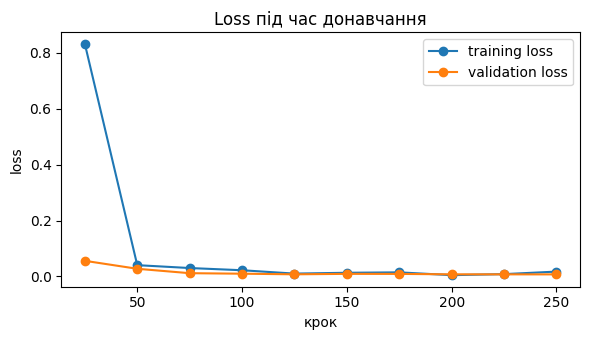

Мінімальний validation loss на кроці 250 із 250


In [17]:
# Таблиця й графік training / validation loss
hist = trainer.state.log_history
train_log = {h["step"]: h["loss"] for h in hist if "loss" in h}
eval_log = {h["step"]: h["eval_loss"] for h in hist if "eval_loss" in h}
steps = sorted(set(train_log) | set(eval_log))
loss_df = pd.DataFrame({
    "step": steps,
    "train_loss": [train_log.get(s) for s in steps],
    "val_loss": [eval_log.get(s) for s in steps],
})
display(loss_df.round(4))

plt.figure(figsize=(6, 3.5))
plt.plot(loss_df["step"], loss_df["train_loss"], marker="o", label="training loss")
plt.plot(loss_df["step"], loss_df["val_loss"], marker="o", label="validation loss")
plt.xlabel("крок"); plt.ylabel("loss"); plt.legend(); plt.title("Loss під час донавчання")
plt.tight_layout(); plt.show()

best_step = loss_df.loc[loss_df["val_loss"].idxmin(), "step"]
print(f"Мінімальний validation loss на кроці {best_step} із {MAX_STEPS}")

**Криві (250 кроків, ≈ 0,67 епохи).** Validation loss майже монотонно знижується з 0,0560 (крок 25) до 0,0075 (крок 250); невеликий відскок був на кроках 150–175 (0,0094 і 0,0092), далі спад триває, мінімум припав на останній крок.
Training loss у першій точці (0,83) — це середнє за перші 25 кроків, коли модель ще вчила формат відповіді (імовірно, з урахуванням warmup); вже на кроці 50 він падає до 0,04, і далі коливається в межах 0,005–0,04
(кожна точка — середнє лише за 25 кроків по 8 прикладів, тому шумна). Train і validation loss одного порядку й не розходяться.

**Ознак перенавчання немає, тому гіперпараметри я не змінювала.** Це й очікувано: за 250 кроків із батчем 8 модель побачила 2000 різних прикладів із 3000 і жоден не повторився,
тобто навіть training loss тут рахувався на ще не баченому прикладі. Validation loss наприкінці ще трохи знижується (0,0077 → 0,0076 → 0,0075 за кроки 200–250),
тож є невеликий запас для довшого тренування, але приріст, імовірно, малий.

Примітка щодо інтерпретації: через `assistant_only_loss=True` loss усереднюється лише по кількох токенах відповіді (слово-мітка й токен кінця репліки),
тому значення малі, а різниця між «майже правильно» і «правильно» на loss видна слабо. Тому підсумкову якість дивимось за метриками на тестовому наборі.

## 1.5. Порівняння до і після

In [18]:
# Оцінка «після» на тому самому тестовому наборі, з КОРОТКИМ промптом (без визначення й прикладів)
tuned = trainer.model
t0 = time.time()
after_metrics, preds_after, answers_after = evaluate(tuned, test_texts, test_targets, SHORT_PROMPT)
after_seconds = time.time() - t0

compare_df = pd.DataFrame({
    "Найчастіший клас": majority_metrics,
    "TF-IDF + LogReg": tfidf_metrics,
    f"Qwen3 до ({best_name})": before_metrics,
    "Qwen3 + LoRA після (короткий промпт)": after_metrics,
}).round(1)
display(compare_df)

n_before = len(tokenizer(BEST_PROMPT)["input_ids"])
n_after = len(tokenizer(SHORT_PROMPT)["input_ids"])
print(f"Токенів у промпті: до — {n_before}, після — {n_after}")
print(f"Час оцінювання 1000 прикладів: до — {before_seconds:.0f} с, після — {after_seconds:.0f} с")

,Найчастіший клас,TF-IDF + LogReg,Qwen3 до (P3 з визначенням і 6 прикладами),Qwen3 + LoRA після (короткий промпт)
"Accuracy, %",49.2,94.4,83.9,96.7
"Precision (TOXIC), %",0.0,94.0,82.0,98.4
"Recall (TOXIC), %",0.0,95.1,87.6,95.1
"F1 (TOXIC), %",0.0,94.5,84.7,96.7
"Macro-F1, %",33.0,94.4,83.9,96.7
"Невалідних відповідей, %",0.0,0.0,0.0,0.0
"Чиста відповідь, %",NaN,NaN,100.0,100.0


Токенів у промпті: до — 296, після — 20
Час оцінювання 1000 прикладів: до — 119 с, після — 68 с


In [19]:
# Ті самі 10 прикладів до і після (⚠️ можливі нецензурні слова)
examples = pd.DataFrame({
    "text": [test_texts[i][:90].replace("\n", " ") for i in show_idx],
    "еталон": [test_targets[i] for i in show_idx],
    "до": [answers_before[i] for i in show_idx],
    "після": [answers_after[i] for i in show_idx],
})
examples

,text,еталон,до,після
0,вмієш бути підаром то будь ним всєгда,TOXIC,TOXIC,TOXIC
1,@caliwinter насправді камера в моєму телефоні ...,NOT_TOXIC,NOT_TOXIC,NOT_TOXIC
2,значить в мене будуть самі круті макети!),NOT_TOXIC,TOXIC,NOT_TOXIC
3,@tinawine ой я ще забула про Castle,NOT_TOXIC,NOT_TOXIC,NOT_TOXIC
4,Статево найчутливіші місця тут — ділянка слизо...,NOT_TOXIC,NOT_TOXIC,NOT_TOXIC
5,@tetyanka_bell ага),NOT_TOXIC,NOT_TOXIC,NOT_TOXIC
6,@doc_vanya але я сиділа й думала: скільки це м...,TOXIC,TOXIC,TOXIC
7,їба,TOXIC,TOXIC,TOXIC
8,Його переможцем визнали компанію Mittal Steel ...,NOT_TOXIC,NOT_TOXIC,NOT_TOXIC
9,@khariton_off збираюсь поступати в Х. Совпадєн...,NOT_TOXIC,NOT_TOXIC,NOT_TOXIC


### Аналіз помилок донавченої моделі

In [20]:
res = pd.DataFrame({
    "text": test_texts, "target": test_targets, "before": preds_before, "after": preds_after, "answer_after": answers_after,
})
res["ok_before"] = res["before"] == res["target"]
res["ok_after"] = res["after"] == res["target"]
res["len"] = res["text"].str.len()

print("Матриця помилок після донавчання (рядки — еталон, стовпці — відповідь моделі):")
print(pd.crosstab(res["target"], res["after"].fillna("INVALID")))

print("\nЗміна правильності (рядки — до, стовпці — після):")
print(pd.crosstab(res["ok_before"].map({True: "правильно до", False: "помилка до"}),
                  res["ok_after"].map({True: "правильно після", False: "помилка після"})))

res["len_bin"] = pd.qcut(res["len"], 4, duplicates="drop")
print("\nЧастка помилок після донавчання за довжиною тексту (у символах):")
print((1 - res.groupby("len_bin", observed=True)["ok_after"].mean()).round(3))

Матриця помилок після донавчання (рядки — еталон, стовпці — відповідь моделі):
after      NOT_TOXIC  TOXIC
target                     
NOT_TOXIC        484      8
TOXIC             25    483

Зміна правильності (рядки — до, стовпці — після):
ok_after      помилка після  правильно після
ok_before                                   
помилка до               20              141
правильно до             13              826

Частка помилок після донавчання за довжиною тексту (у символах):
len_bin
(1.999, 41.0]      0.020
(41.0, 77.0]       0.040
(77.0, 120.25]     0.061
(120.25, 424.0]    0.012
Name: ok_after, dtype: float64


In [21]:
def show_errors(mask, title, k=10):
    print(f"\n===== {title}: {int(mask.sum())} шт.; показано {min(k, int(mask.sum()))} =====")
    for _, row in res[mask].head(k).iterrows():
        print(f"[еталон {row['target']:<9} | модель {row['after']}] {row['text'][:150]!r}")


show_errors((res["target"] == "NOT_TOXIC") & (~res["ok_after"]), "Хибні спрацювання: нормальне повідомлення назване токсичним")
show_errors((res["target"] == "TOXIC") & (~res["ok_after"]), "Пропуски: токсичне повідомлення не знайдено")
show_errors(res["ok_before"] & ~res["ok_after"], "Стало гірше: було правильно до, помилка після", k=5)


===== Хибні спрацювання: нормальне повідомлення назване токсичним: 8 шт.; показано 8 =====
[еталон NOT_TOXIC | модель TOXIC] 'відповідальність громади - це ок, але й центральна влада має гарантувати стандарти, поцікавтесь, у скількох ОТГ діють служби чи уповноважені у справах'
[еталон NOT_TOXIC | модель TOXIC] 'Піздєц, півстрічки жере, і ти туди ж. Я вже не витримую.'
[еталон NOT_TOXIC | модель TOXIC] '@Lazzio90 ну хіба.. словом, закручено все. Курва, як завжди'
[еталон NOT_TOXIC | модель TOXIC] '@Fresh_UA_ давай, дєрзай'
[еталон NOT_TOXIC | модель TOXIC] "fuck a, Мар'ян"
[еталон NOT_TOXIC | модель TOXIC] 'даже лежачи на смертному одрі, якшо хтось пошутить про псіну сутулу я в галасіну заржу'
[еталон NOT_TOXIC | модель TOXIC] 'мама:"я там таке відео в ютюбі бачила..."\nтато:"ну, яке?"\nя(в думках):"чорт візьми мамо ти знаєш що таке ютюб ?"'
[еталон NOT_TOXIC | модель TOXIC] '@Igorko_Sokil а якщо дівчина сама може за себе все оплатити і плюс любить куверкатись також¿ #fuck_the_system'


**Загальна картина.** Після донавчання 33 помилки з 1000 (3,3%): 8 хибних спрацювань і 25 пропусків (матриця помилок: 484 / 8 / 25 / 483). Модель стала **обережнішою**: хибних спрацювань 8 проти ≈ 98 до донавчання,
пропусків 25 проти ≈ 63. З 161 помилки «до» виправлено 141, але з'явилось 13 нових помилок («стало гірше»); 20 прикладів лишились помилковими в обох випадках, 826 були правильні в обох.

**Хибні спрацювання (усі 8):**

1. **Явна лайка, а еталон NOT_TOXIC — 4 з 8:** «П***єц, півстрічки жере…», «К***а, як завжди», «f**k a, Мар'ян», «#f**k_the_system». На мій погляд, це **шум розмітки**: або словник ключових слів неповний,
   або він не охоплює англійську (обидва «f**k» мають мітку NOT_TOXIC). Тут модель, імовірно, права, а еталон хибний.
2. **Справжні помилки моделі (надчутливість) — 4 з 8:** нейтральне «відповідальність громади — це ок, але й центральна влада має гарантувати стандарти…» (жодної лайки), «давай, дєрзай», жартівливе «псіну сутулу»,
   м'який вигук «чорт візьми, мамо…».

**Пропуски (показано 10 з 25):**

1. **Образливі слова-слюри й сленг, які модель не вважає токсичними — 7 з 10:** «тьолка» (двічі), «педик(и)» (двічі), «хохол», «жидівськи», «нігадяй». Тобто конвенція `TOXIC` у датасеті **ширша за лайку**: включає зневажливі й дискримінаційні слова.
   Окремо: «жидівськи кнайпу» набрано з латинською `i` замість української `і` («пiсля», «жидiвськи»), що ускладнює токенізацію й розпізнавання.
2. **Шум розмітки — 3 з 10:** «задрімала на педікюрі…» і «велосипедик, дякую…» мають мітку TOXIC, імовірно, через збіг підрядка «педик/педік» із ключовим словом, а «університет в снігах — це одне з найгарніших видив» — безневинне речення без очевидної причини мітки.

**Коротші тексти, контекст, сарказм.** Припущення про «короткі тексти без контексту» не підтвердилось: частка помилок за довжиною (у символах) — ≤ 41: 2,0%; 42–77: 4,0%; 78–120: 6,1%; > 120: 1,2%.
Найбільше помилок у середніх за довжиною текстах, а найдовші тексти (імовірно, новини й проза, нетоксичні) класифікуються майже безпомилково.

**«Стало гірше» (13):** п'ять показаних прикладів — усі слюри й сленг («тьолка», «жидівськи», «педикам», «педик-айпедик»). Імовірно, загальне уявлення про образливість у базової моделі з промптом P3 вловлювало їх,
а після SFT на 3000 прикладах модель орієнтується на лексику, яку частіше бачила в даних, і слабше реагує на рідкісні слюри (це припущення, окремо я його не перевіряла).

**Перевірка припущень.**
(а) *Джерело замість токсичності:* прямих доказів немає, але частка помилок мінімальна саме на найдовших текстах (1,2%), що узгоджується з гіпотезою: довгі нетоксичні тексти — з іншого регістру (новини, проза), і їх легко відрізнити від коротких твітів.
Тож 96,7% на цьому тесті не можна автоматично переносити на інший домен. (б) *TF-IDF проти LLM:* так, лексична природа розмітки підтверджується: TF-IDF дає 94,4% (до донавчання LLM із промптом мала лише 83,9%),
тобто більшу частину сигналу ловить проста лексика. Донавчена модель додає ще ≈ 2,3 п.п. accuracy (≈ 23 приклади із 1000; один прогін, тож обережно).

### Чи не погіршилися загальні відповіді моделі

Після SFT на вузькій задачі модель могла «забути» інше (catastrophic forgetting) або почати відповідати `TOXIC` / `NOT_TOXIC` на будь-який запит.
Порівнюємо відповіді моделі **з адаптером і без нього** (`disable_adapter()`) на запити поза нашою задачею.

In [22]:
general_prompts = [
    "Поясни простими словами, що таке фотосинтез.",
    "Translate to English: «Доброго ранку! Як ваші справи?»",
    "Write a Python function that returns the n-th Fibonacci number.",
    "Яка столиця Франції і чим вона відома?",
    "Напиши коротке привітання колезі з днем народження українською мовою.",
]


def chat(model, user_message, max_new_tokens=150):
    prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": user_message}], tokenize=False, add_generation_prompt=True, enable_thinking=False,
    )
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()


tuned.eval()
label_only = 0
for q in general_prompts:
    with tuned.disable_adapter():            # оригінальна модель без адаптера
        base_answer = chat(tuned, q)
    tuned_answer = chat(tuned, q)            # модель з адаптером
    label_only += tuned_answer.strip().upper() in LABELS
    print(f"❓ {q}\n\n🔹 БЕЗ адаптера:\n{base_answer}\n\n🔸 З адаптером:\n{tuned_answer}\n" + "=" * 70 + "\n")
print(f"Відповідей, які звелись до слова-мітки: {label_only} із {len(general_prompts)}")

❓ Поясни простими словами, що таке фотосинтез.

🔹 БЕЗ адаптера:
Фотосинтез — це процес, який росливи і тварини виконують, щоб створити їхній їжі і енергію. Це дуже важливе для землі, бо він допомагає зберігати повітря і створювати рослини, які використовують для їжі.

### Як це робиться?

1. **Під час сонця**: Рослини, тварини і інші органі

🔸 З адаптером:
Фотосинтез — це процес, який росливи і тварини виконують, щоб створити їхні їжу і енергію. Це відбувається в хвої, листях, коренях і інших органів рослин.

### Як це робиться?

1. **Підходячи до сонця**: Рослини мають листя, яке відчуває сонячну вітру. Вони відчувають, що

❓ Translate to English: «Доброго ранку! Як ваші справи?»

🔹 БЕЗ адаптера:
Good morning! How are your affairs?

🔸 З адаптером:
Good morning! How are your affairs?

❓ Write a Python function that returns the n-th Fibonacci number.

🔹 БЕЗ адаптера:
Sure! Here's a Python function that returns the **n-th Fibonacci number**:

```python
def fibonacci(n):
    if n <= 0:
  

**Висновок за 5 загальними запитами** (жадібне декодування, ліміт 150 токенів; частину відповідей обірвано лімітом):

- **Колапсу немає:** 0 із 5 відповідей звелись до слова-мітки `TOXIC` / `NOT_TOXIC`; модель з адаптером далі відповідає на загальні запити по суті й тією ж мовою.
- **Переклад** (Good morning! How are your affairs?) — відповіді з адаптером і без нього **ідентичні**. **Код (Фібоначчі)** — обидва варіанти правильні: без адаптера ітеративний, з адаптером рекурсивний (коректний, але менш ефективний).
  **Столиця Франції** — обидва відповідають «Париж», з адаптером додаткові пояснення дещо повторюються («міста-центру» тричі).
- **Помітні слабкі місця.** У відповіді про фотосинтез обидві версії містять огріхи української («росливи» в обох; у версії з адаптером ще й «сонячну вітру»): різниця невелика, а головна причина — обмеженість самої моделі 1,7B у вільній генерації українською.
  **Єдина явно слабша відповідь з адаптером — привітання колезі:** без адаптера були слова «З днем народження!», а з адаптером — лише «Добрий день, колезі! 🎉 З повагою, [Ваше ім'я]» без самого привітання.
- **Обережно з висновками:** п'ять запитів і жадібне декодування — це швидка діагностика, а не статистика. Заміну в одному запиті можна пояснити й випадковістю. Загалом збереження загальних можливостей виглядає непоганим:
  LoRA змінює близько 1% параметрів (17,4 млн із 1,74 млрд), що обмежує вплив на решту моделі, але одна з п'яти відповідей стала помітно гіршою.

In [23]:
# Збереження адаптера (ваги в репозиторій НЕ додаємо: лише локально або на Hugging Face Hub)
ADAPTER_DIR = "qwen3-1.7b-uk-toxicity-lora-adapter"
trainer.save_model(ADAPTER_DIR)
print(f"Розмір адаптера: {os.path.getsize(os.path.join(ADAPTER_DIR, 'adapter_model.safetensors')) / 1e6:.1f} MB")

# Необовʼязково (+1 бонусний бал): публікація адаптера на Hugging Face Hub.
# Розкоментуйте, виконайте вхід і вставте посилання у звіт. Вказуйте ліцензію OpenRAIL++, як у датасету.
# from huggingface_hub import notebook_login
# notebook_login()
# trainer.model.push_to_hub("YOUR_USERNAME/qwen3-1.7b-uk-toxicity-lora")
# tokenizer.push_to_hub("YOUR_USERNAME/qwen3-1.7b-uk-toxicity-lora")

Розмір адаптера: 69.8 MB


---
## 1.6. Мій звіт

**Задача і чому потрібне донавчання:**
Класифікація україномовних повідомлень на `TOXIC` / `NOT_TOXIC` для модерації чатів і коментарів. Вхід — одне коротке повідомлення, вихід — одне слово. Користувач — модератор спільноти, система ховає повідомлення або позначає його для ручної перевірки.
Гіпотези, чому не вистачає промпту, і що показав експеримент:
(1) мітка `TOXIC` — це конвенція розмітки, яку складно описати текстом: **підтвердилось**. Визначення в промпті майже не допомогло (recall 47,0%), і лише 6 прикладів у промпті дали якість 86,7% F1 на validation;
(2) довгий промпт множиться на потік запитів: **підтвердилось**: промпт із прикладами — 296 токенів, після донавчання достатньо 20, а час оцінювання 1000 прикладів скоротився з 119 до 68 с;
(3) жорсткий формат відповіді: **не підтвердилось**: Qwen3-1.7B видає чисту відповідь у 100% випадків і без донавчання;
(4) RAG не підходить (немає бази знань, проблема в межі рішення), а (5) приватність власного сервера я окремо не перевіряла.

**Модель і дані:**
Qwen3-1.7B (`Qwen/Qwen3-1.7B`, post-trained, 1,72 млрд параметрів, fp16, режим міркування вимкнено): instruct-версія, щоб промптовий базовий рівень був чесним; підтримує українську; вміщується в T4 (3,4 GB ваг).
Дані: `ukr-detect/ukr-toxicity-dataset-seminatural` (OpenRAIL++), parquet, колонки `text` і `tags`; розмітка напівавтоматична, за ключовими словами. Вихідні поділи: train 12 682 / validation 4 227 / test 4 214.
Очищення: 113 прикладів без мітки (`None`) видалено, дублікати й перетини між наборами прибрано (train 12 536, validation 4 195, test 4 200). Підвибірки: **train 3000** (1495 TOXIC / 1505 NOT_TOXIC), **validation 300** (151 / 149), **test 1000** (508 / 492).
Тест не використовувався ні для тренування, ні для вибору промпту.

**Метрика й результат до донавчання:**
Головна метрика — F1 для класу `TOXIC` (ціна помилок різна: хибні спрацювання ховають нормальні повідомлення, пропуски пропускають лайку), додатково accuracy, precision, recall, macro-F1, частка невалідних і «чистих» відповідей.
Базові рівні на тесті: найчастіший клас — accuracy 49,2%, F1 0; TF-IDF + LogReg (символьні n-грами) — accuracy 94,4%, F1 94,5%.
Найкращий промпт, вибраний на validation: P3 (визначення + 6 прикладів, 296 токенів), F1 86,7% на validation (P1: 55,5%, P2: 61,7%).
Результат P3 на тесті: **accuracy 83,9%, F1 (TOXIC) 84,7%**, precision 82,0%, recall 87,6%, чистих відповідей 100%; оцінювання 119 с.

**Метод донавчання й гіперпараметри:**
SFT з LoRA (TRL + PEFT): `r=16`, `lora_alpha=32`, dropout 0.05, усі лінійні шари; learning rate 2e-4 (cosine, warmup 10); ефективний батч 8 (4 × 2); 250 кроків (≈ 0,67 епохи, 2000 прикладів);
loss лише на відповіді асистента; fp16 і gradient checkpointing; `max_length=256` (у перевірених 300 прикладах максимальна довжина діалогу — 235 токенів). Тренувальний промпт — короткий (P1, 20 токенів).
Тренованих параметрів: 17 432 576 (1,00%). **Тривалість тренування: 7,3 хв. Пікова памʼять GPU: 4,1 GB.** Розмір адаптера: 69,8 MB. Перенавчання не виявлено (validation loss знизився з 0,056 до 0,0075 і мінімальний на останньому кроці), тому гіперпараметри не змінювались.

**Результат після донавчання:**
З коротким промптом (20 токенів): **accuracy 96,7%, F1 (TOXIC) 96,7%**, precision 98,4%, recall 95,1%, macro-F1 96,7%, невалідних відповідей 0%, чистих 100%.
Проти моделі «до» (P3): **+12,8 п.п. accuracy, +12,0 п.п. F1**, precision +16,4 п.п., recall +7,5 п.п., промпт коротший у ≈ 15 разів (296 → 20 токенів), оцінювання швидше на 43% (119 → 68 с).
Проти TF-IDF + LogReg: +2,3 п.п. accuracy і +2,2 п.п. F1 (≈ 23 приклади із 1000; один прогін). Помилок стало 33 замість 161: хибних спрацювань 8 (було ≈ 98), пропусків 25 (було ≈ 63); виправлено 141 приклад, зіпсовано 13.
Для довідки: на validation той самий короткий промпт P1 без донавчання давав лише 67,3% accuracy.

**Аналіз помилок:**
Хибні спрацювання (8): половина — явна лайка з міткою NOT_TOXIC (шум розмітки, зокрема англійське «f**k»), половина — справжня надчутливість моделі на нейтральних і жартівливих фразах.
Пропуски (25, показано 10): у більшості — образливі слюри й сленг («тьолка», «педик», «хохол», «жидівськи»), яких модель не вважає токсичними; конвенція датасету ширша за лайку. Ще 3 з 10 — шум розмітки (підрядок «педик» у «педікюр», «велосипедик»).
Серед 13 «зіпсованих» донавчанням прикладів показані п'ять — слюри й сленг. Частка помилок за довжиною: ≤ 41 символ — 2,0%, 42–77 — 4,0%, 78–120 — 6,1%, > 120 — 1,2%.
Перевірка загальних запитів (5 запитів): колапсу в мітки немає, переклад ідентичний, код правильний; є одна слабша відповідь (привітання без слів «З днем народження»), решта — на рівні базової моделі з її власними огріхами української.

**Висновок:**
Донавчання виправдане щодо промптингу: LoRA за 7,3 хв на T4 підняла F1 з 84,7% до 96,7% і водночас скоротила промпт із 296 до 20 токенів і час оцінювання на 43%. Формат відповіді проблемою не був.
Проте проти простого TF-IDF + LogReg виграш скромний (≈ 2,3 п.п. accuracy): розмітка здебільшого лексична, тож для цієї задачі на цих даних класичний класифікатор — серйозна альтернатива за вартістю й швидкістю, а перевага LLM залежить від того, чи потрібна робота зі складнішим контекстом.
Обмеження: напівавтоматична розмітка (шум: частина «помилок» моделі — це помилки еталона, тож реальна якість, імовірно, вища за виміряну), різний регістр класів (довгі нетоксичні тексти з новин і прози, тоді як токсичні — короткі твіти), результати не перевірено на іншому домені,
один прогін із одним seed (без довірчих інтервалів), 5 запитів для перевірки загальних можливостей. Що зробила б далі: чистіша (краудсорсингова) розмітка або перегляд міток, у яких модель та еталон розходяться; перевірка на даних з іншого джерела;
порівняння з енкодером на кшталт XLM-R із новою головою; довше тренування й кілька seed. Посилання на адаптер на Hugging Face Hub: не публікувався (бонус необов'язковий).